In [1]:
import uproot
import keras
import tensorflow
import awkward as ak
from sklearn.model_selection import train_test_split

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import vector 

In [3]:
df_reco=uproot.concatenate('/Users/rokitkumar/Documents/Raml/ttbar_FS_ntuple.root',  
                           library='pd', 
                           filter_name=['bjet*', 'jet*', 'event*', 'el*', 'mu*', 'm_*', 'M*', 'event_wgt_NOSYS', '*case*', '*charge*', 'met*'])

In [4]:
df_reco.columns

Index(['ME_m_tt', 'Mbbll_reco_NOSYS', 'Mtt_regress_NOSYS', 'bjet0_E_NOSYS',
       'bjet0_eta_NOSYS', 'bjet0_phi_NOSYS', 'bjet0_pt_GeV_NOSYS',
       'bjet1_E_NOSYS', 'bjet1_eta_NOSYS', 'bjet1_phi_NOSYS',
       'bjet1_pt_GeV_NOSYS', 'el0_E_NOSYS', 'el0_eta_NOSYS', 'el0_phi_NOSYS',
       'el0_pt_GeV_NOSYS', 'eventNumber', 'event_wgt_NOSYS',
       'm_b1_b2_GeV_NOSYS', 'm_b1_b2_dR_NOSYS', 'm_b1_met_GeV_NOSYS',
       'm_b2_met_GeV_NOSYS', 'm_el_b1_GeV_NOSYS', 'm_el_b2_GeV_NOSYS',
       'm_el_met_GeV_NOSYS', 'm_el_mu_GeV_NOSYS', 'm_el_mu_dR_NOSYS',
       'm_mu_b1_GeV_NOSYS', 'm_mu_b2_GeV_NOSYS', 'm_mu_met_GeV_NOSYS',
       'met_met_GeV_NOSYS', 'met_phi_NOSYS', 'mu0_E_NOSYS', 'mu0_charge_NOSYS',
       'mu0_eta_NOSYS', 'mu0_phi_NOSYS', 'mu0_pt_GeV_NOSYS',
       'ttbar_case_NOSYS'],
      dtype='str')

In [5]:
df_reco.shape 

(9926115, 37)

In [6]:
#every row is a unique particle collision event and every column is a speicific physik measurements like bjet0_E_NOSYS

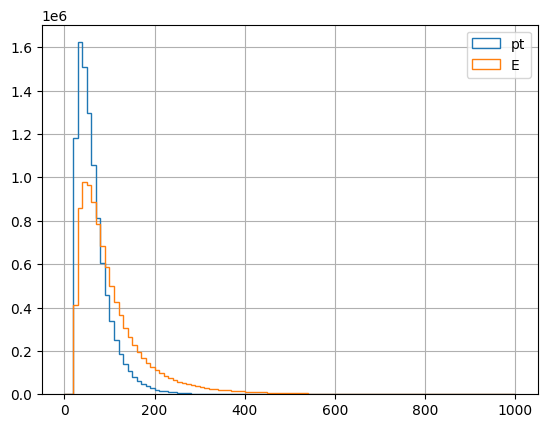

In [7]:
df_reco['el0_pt_GeV_NOSYS'].hist(histtype='step', range=(0,1e3), bins=100, label='pt')
(df_reco['el0_E_NOSYS']/1000).hist(histtype='step', range=(0,1e3), bins=100, label='E')
plt.legend()

In [8]:
#pt has stacked up higher peak at lower value this means that very few electrons are shot out perpendicularly (90 degrees sideways) into the heart of the detector.

In [9]:
print(tensorflow.__version__,pd.__version__,keras.__version__)

2.21.0 3.0.3 3.14.1


In [10]:
df_truth=uproot.concatenate('/Users/rokitkumar/Documents/Raml/ttbar_FS_ntuple.root',
                           library='pd',
                           filter_name=['truth_*','eventNumber'])

In [11]:
df_truth.columns

Index(['eventNumber', 'truth_Eta_top_CM', 'truth_P_top_CM',
       'truth_costh_top_CM', 'truth_dY_tt', 'truth_m_tt'],
      dtype='str')

In [12]:
#truth_m_tt - Invariant Mass of the ttbar System 
#truth_dY_tt - Rapidity Difference 
#truth_Eta_top_CM - Pseudorapidity in the Center-of-Mass Frame
#truth_costh_top_CM - Cosine of Theta in the Center-of-Mass Frame
#truth_P_top_CM - Momentum in the Center-of-Mass Frame

In [13]:
#eventNumber is  an identification number, like a passport number for that specific collision. It has no physical or mathematical meaning.

In [14]:
#Mbbll_reco_NOSYS is the combined reconstructed mass of all those decay pieces added together.2bjets and 2leptons for each event.
#this is physics equation guessed values, this is used as a feature for the neuralnetwork to learn effectively.

In [15]:
df_reco.head()

,ME_m_tt,Mbbll_reco_NOSYS,Mtt_regress_NOSYS,bjet0_E_NOSYS,bjet0_eta_NOSYS,bjet0_phi_NOSYS,bjet0_pt_GeV_NOSYS,bjet1_E_NOSYS,bjet1_eta_NOSYS,bjet1_phi_NOSYS,...,m_mu_b2_GeV_NOSYS,m_mu_met_GeV_NOSYS,met_met_GeV_NOSYS,met_phi_NOSYS,mu0_E_NOSYS,mu0_charge_NOSYS,mu0_eta_NOSYS,mu0_phi_NOSYS,mu0_pt_GeV_NOSYS,ttbar_case_NOSYS
0,496079.81250,295.596222,422.455353,127475.828125,1.137303,1.977037,73.980347,232568.609375,2.353900,2.451699,...,88.623222,79.188881,62.112514,0.976079,44990.000000,1.0,1.004659,-0.784825,29.052477,2
1,591921.56250,409.585724,600.380249,166914.375000,0.327795,-0.070266,157.050720,153194.343750,-0.153311,3.083174,...,196.984421,119.492973,53.114170,-2.998959,69455.187500,1.0,-0.183650,0.456727,68.300079,2
2,366981.40625,206.276810,375.023376,202727.843750,1.414018,-1.313673,93.008270,116289.312500,1.629376,-0.298832,...,71.155190,119.344261,91.956261,1.890086,116138.226562,-1.0,1.749684,1.730418,39.192085,3
3,601024.06250,443.821625,630.922180,201098.203125,0.279258,2.433943,191.996796,91957.312500,0.633235,0.351059,...,131.949661,62.262478,119.579552,-0.545876,136944.281250,1.0,0.227968,-0.986128,133.461227,1
4,600065.00000,355.624664,613.243958,300389.093750,2.078774,-1.965004,73.975937,78530.703125,-0.417869,-0.498912,...,170.072632,152.119965,92.974426,1.965831,122564.421875,-1.0,2.192579,-2.676905,27.026567,3


In [16]:
df_truth.head()

,eventNumber,truth_Eta_top_CM,truth_P_top_CM,truth_costh_top_CM,truth_dY_tt,truth_m_tt
0,195473384,-0.674341,178259.015625,-0.587828,-0.914755,494.983368
1,195473757,0.143591,239635.843750,0.142612,0.229357,586.218384
2,195549461,-1.487304,67325.726562,-0.902828,-0.662172,370.210846
3,195354567,0.190812,246667.125000,0.188529,0.285533,600.350769
4,195354585,-2.161654,245812.062500,-0.973835,-2.187536,602.237061


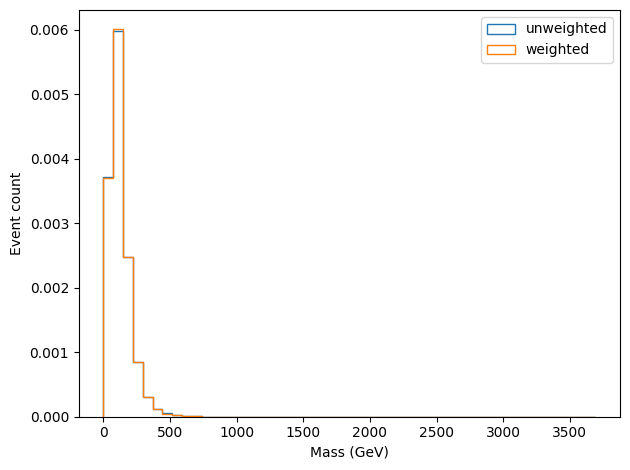

In [17]:
plt.hist(df_reco['m_el_mu_GeV_NOSYS'], bins=50, histtype='step', label='unweighted', density=True)
plt.hist(df_reco['m_el_mu_GeV_NOSYS'], bins=50, weights=df_reco['event_wgt_NOSYS'], histtype='step', label='weighted', density=True)

for ax in plt.gcf().axes:
    ax.set_xlabel('Mass (GeV)')
    ax.set_ylabel('Event count')

plt.tight_layout()
plt.legend()
plt.show()
#A validation plot comparing the unweighted data distribution against the data corrected by event_wgt_NOSYS

In [18]:
# Weighted vs unweighted curves align perfectly. This confirms the baseline 
# Monte Carlo simulation matches expected physical distributions without 
# requiring severe reweighting, providing a balanced training dataset.

In [19]:
#MERGING SIMULATION TABLE AND TRUTH TABLE 

In [20]:
df_list = []
df_reco.set_index("eventNumber")
df_truth.set_index("eventNumber")
df = pd.merge(df_reco, df_truth)  
df_list.append(df)

In [21]:
df = pd.concat(df_list, ignore_index=True)
del df_list
del df_reco
del df_truth

In [22]:
df.head()

,ME_m_tt,Mbbll_reco_NOSYS,Mtt_regress_NOSYS,bjet0_E_NOSYS,bjet0_eta_NOSYS,bjet0_phi_NOSYS,bjet0_pt_GeV_NOSYS,bjet1_E_NOSYS,bjet1_eta_NOSYS,bjet1_phi_NOSYS,...,mu0_charge_NOSYS,mu0_eta_NOSYS,mu0_phi_NOSYS,mu0_pt_GeV_NOSYS,ttbar_case_NOSYS,truth_Eta_top_CM,truth_P_top_CM,truth_costh_top_CM,truth_dY_tt,truth_m_tt
0,496079.81250,295.596222,422.455353,127475.828125,1.137303,1.977037,73.980347,232568.609375,2.353900,2.451699,...,1.0,1.004659,-0.784825,29.052477,2,-0.674341,178259.015625,-0.587828,-0.914755,494.983368
1,591921.56250,409.585724,600.380249,166914.375000,0.327795,-0.070266,157.050720,153194.343750,-0.153311,3.083174,...,1.0,-0.183650,0.456727,68.300079,2,0.143591,239635.843750,0.142612,0.229357,586.218384
2,366981.40625,206.276810,375.023376,202727.843750,1.414018,-1.313673,93.008270,116289.312500,1.629376,-0.298832,...,-1.0,1.749684,1.730418,39.192085,3,-1.487304,67325.726562,-0.902828,-0.662172,370.210846
3,601024.06250,443.821625,630.922180,201098.203125,0.279258,2.433943,191.996796,91957.312500,0.633235,0.351059,...,1.0,0.227968,-0.986128,133.461227,1,0.190812,246667.125000,0.188529,0.285533,600.350769
4,600065.00000,355.624664,613.243958,300389.093750,2.078774,-1.965004,73.975937,78530.703125,-0.417869,-0.498912,...,-1.0,2.192579,-2.676905,27.026567,3,-2.161654,245812.062500,-0.973835,-2.187536,602.237061


In [23]:
#INPUT AND TARGET VARIABLES FOR REGRESSION. 

In [24]:
input_features  = ['Mbbll_reco_NOSYS', 'm_el_mu_GeV_NOSYS', 'm_el_b1_GeV_NOSYS', 'm_el_b2_GeV_NOSYS', 'm_mu_b1_GeV_NOSYS', 'm_mu_b2_GeV_NOSYS', 'm_b1_b2_GeV_NOSYS',
 'm_b1_met_GeV_NOSYS', 'm_b2_met_GeV_NOSYS', 'm_el_met_GeV_NOSYS', 'm_mu_met_GeV_NOSYS', 'el0_eta_NOSYS', 'mu0_eta_NOSYS', 'bjet0_eta_NOSYS', 'bjet1_eta_NOSYS','mu0_charge_NOSYS']
target_features = ['truth_m_tt','truth_dY_tt','truth_Eta_top_CM','event_wgt_NOSYS']

X = df[input_features].to_numpy(dtype='float64')
y = df[target_features].to_numpy(dtype='float64')

print(X.dtype,y.dtype)

for i in range(16): print("Input=",np.min(X[:,i]),np.max(X[:,i]),np.mean(X[:,i]),np.std(X[:,i]))
for i in range(4): print("Target=",np.min(y[:,i]),np.max(y[:,i]),np.mean(y[:,i]),np.std(y[:,i]))

float64 float64
Input= 60.720333099365234 4503.0703125 345.4173628880524 144.6819179008418
Input= 0.13872843980789185 3691.01171875 124.23474510108393 81.13423758433667
Input= 11.287239074707031 3145.890625 139.76271748969438 86.57862441340055
Input= 10.405287742614746 1770.9969482421875 106.7610534794979 55.93059484639648
Input= 11.077561378479004 2944.34814453125 134.60675401717603 83.89028676938803
Input= 10.673335075378418 1853.3924560546875 104.94321218629865 56.39150182557583
Input= 12.586302757263184 4235.98828125 163.511928677575 105.2066355496476
Input= 3.0687222480773926 2423.93212890625 156.2079765810814 90.87694888281175
Input= 2.8276846408843994 1422.260498046875 107.93397484164507 57.00905450263785
Input= 0.04631398618221283 1834.4146728515625 112.19303809532721 65.69634924354452
Input= 0.19792485237121582 10164.669921875 111.90114226782666 64.94052862945202
Input= -2.5058958530426025 2.5022377967834473 0.004378268007344595 1.0449837727382294
Input= -2.499999761581421 2.4

In [25]:
#bjet0_E_NOSYS - Total Energy (E) of the first b-jet
#E-total energy    pt-transverse momentum     eta-Pseudorapidity or polar angle    phi-Azimuthal Angle 

In [26]:
#NORMALISATION 

In [27]:
target_norm   =keras.layers.Normalization(axis=-1) #By using axis=-1, Keras scales truth_m_tt based only on other masses, and scales truth_dY_tt based only on other rapidities. Each feature gets its own perfectly tailored scale.
target_denorm =keras.layers.Normalization(axis=-1,invert=True) 
target_norm.adapt(y[:,0:3]) #This tells the machine to study those 3 columns and learn two things:What is their average size?How much do they bounce around from big to small?(sd)
target_denorm.adapt(y[:,0:3])

ynorm=target_norm(y[:,0:3])
ynorm=np.hstack((ynorm,y[:,3:4]))# to avoid normalising weights by not doing so we change the relative values of the weights which changes the physical meaning of those ratios.

In [28]:
# Print 3 rows of the ORIGINAL data (first 3 columns)
print("Before:\n", y[:3, 0:3])

# Print 3 rows of the NORMALIZED data (first 3 columns)
print("\nAfter:\n", ynorm[:3, 0:3].numpy() if hasattr(ynorm, "numpy") else ynorm[:3, 0:3])

Before:
 [[ 4.94983368e+02 -9.14755225e-01 -6.74341023e-01]
 [ 5.86218384e+02  2.29357451e-01  1.43591270e-01]
 [ 3.70210846e+02 -6.62172019e-01 -1.48730433e+00]]

After:
 [[-0.23188388 -0.78910661 -0.61812431]
 [ 0.28927797  0.19769526  0.13116632]
 [-0.9446221  -0.57125252 -1.36286283]]


In [29]:
#SPLITTING TRAINING AND TEST SAMPLES 

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, ynorm, test_size=0.4, random_state=42) # Use normalised variables
len(X_train),len(X_test),X_train.dtype,X_train.shape

(5955669, 3970446, dtype('float64'), (5955669, 16))

In [31]:
#Deep neural network - MLP Multilayered Perceptron

In [32]:
model_improved = keras.models.Sequential([
    keras.layers.Input(shape=(16,)),
    keras.layers.BatchNormalization(), 
    
    keras.layers.Dense(256, activation='swish', kernel_initializer='he_normal'),
    keras.layers.Dropout(0.2), 
    
    keras.layers.Dense(128, activation='swish', kernel_initializer='he_normal'),
    keras.layers.Dropout(0.2),
    
    keras.layers.Dense(64, activation='swish', kernel_initializer='he_normal'),
    
    keras.layers.Dense(3, activation='linear')
])

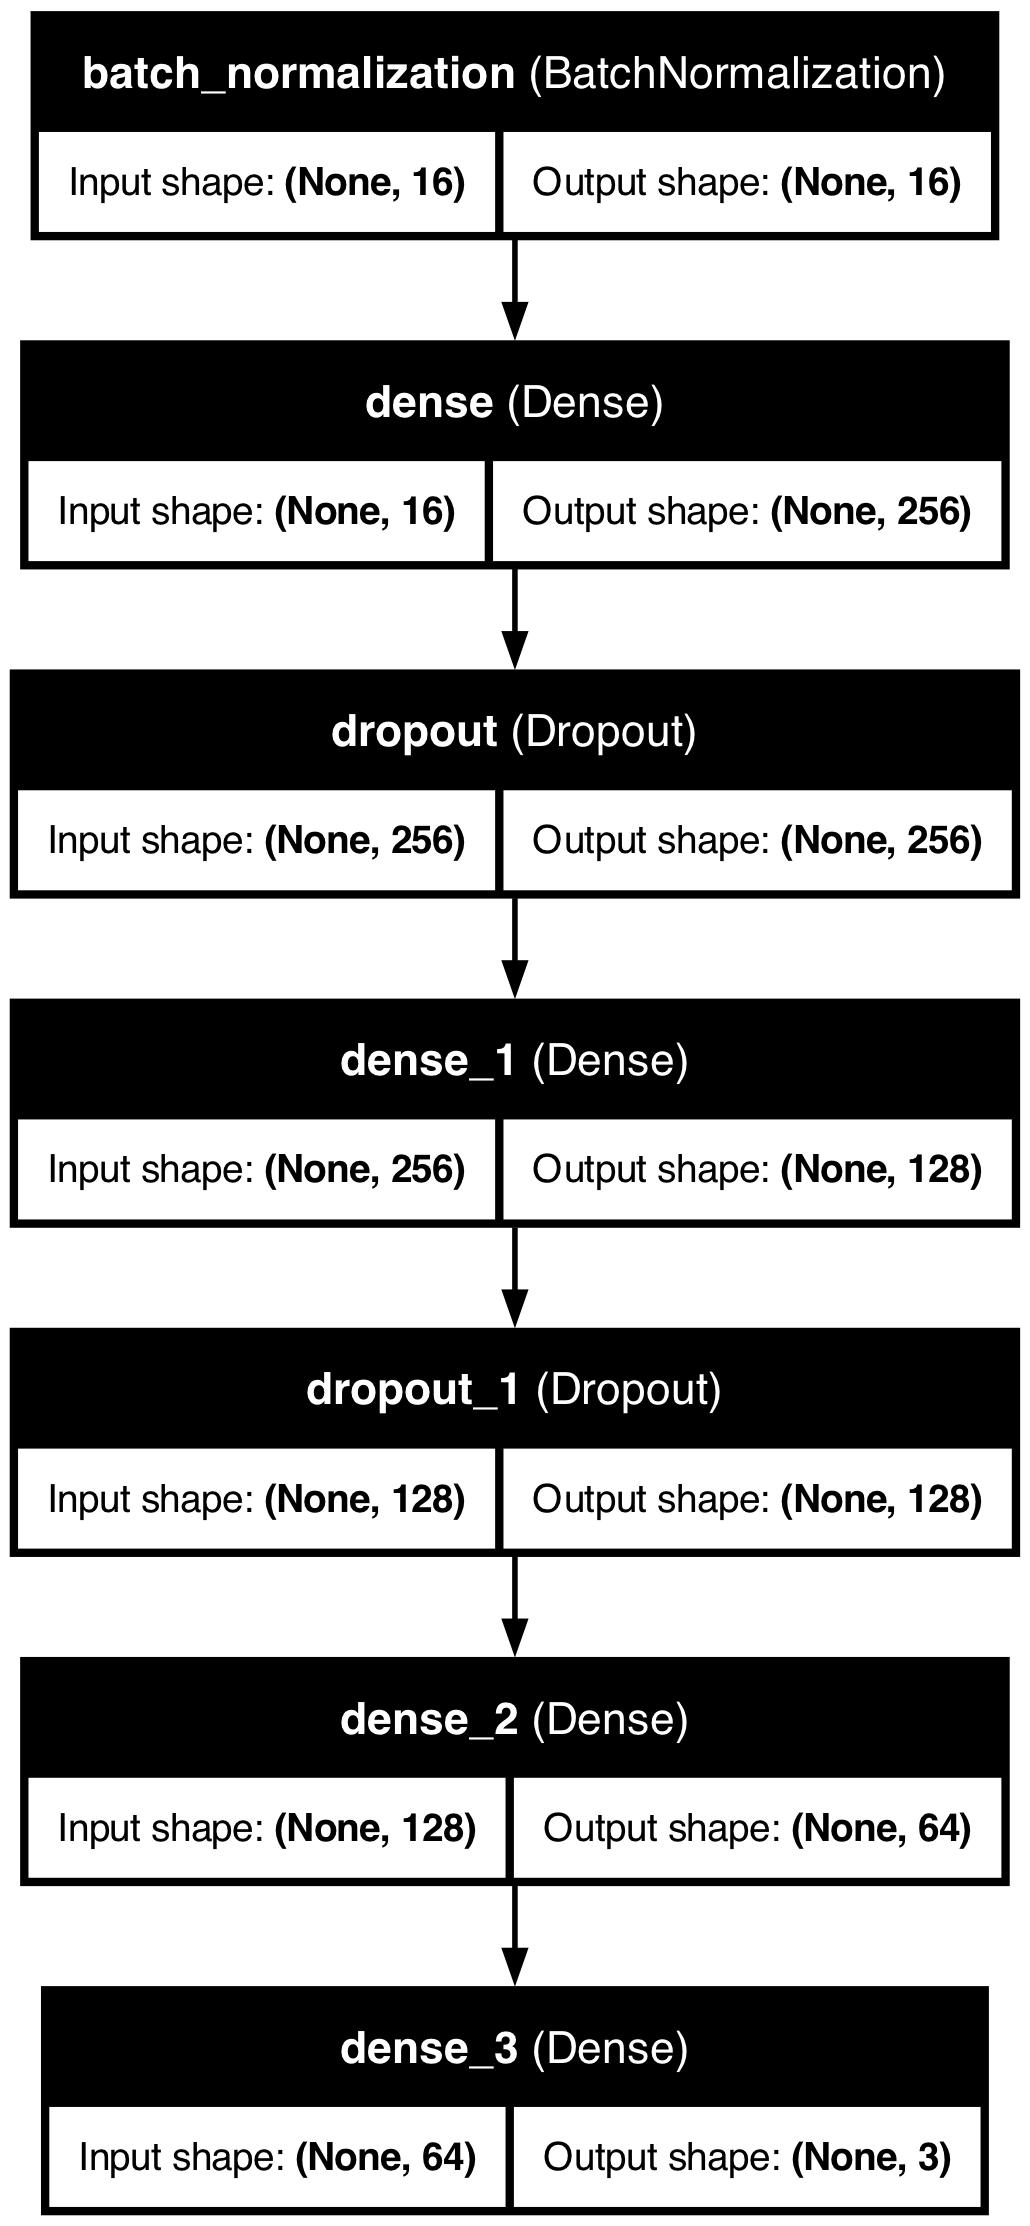

In [33]:
from keras.utils import plot_model
from IPython.display import Image, display

plot_model(model_improved, to_file='./model.png', show_shapes=True, show_layer_names=True)
display(Image('./model.png', width=300))

In [34]:
#Loss Function 

In [35]:
def hybrid_shape_weighted_loss(y, yhat):
    # Extract standard event weights
    wgt = y[:, 3]
    wgtsum = keras.ops.sum(wgt) + 1e-7
    
    # Standard Event-Weighted Mean Squared Error (Individual Accuracy)
    sq_err_1 = keras.ops.square(keras.ops.subtract(y[:, 0], yhat[:, 0]))
    sq_err_2 = keras.ops.square(keras.ops.subtract(y[:, 1], yhat[:, 1]))
    sq_err_3 = keras.ops.square(keras.ops.subtract(y[:, 2], yhat[:, 2]))
    mse_loss = keras.ops.sum(wgt * (sq_err_1 + sq_err_2 + sq_err_3)) / wgtsum

    # Shape Constraints: Calculate Variances (Dispersions)
    # (Since targets are normalized, true variance is around 1, mean is around 0)
    dispYhat = keras.ops.sum(wgt * keras.ops.square(yhat[:, 1])) / wgtsum    
    dispY    = keras.ops.sum(wgt * keras.ops.square(y[:, 1])) / wgtsum    
    dispEhat = keras.ops.sum(wgt * keras.ops.square(yhat[:, 2])) / wgtsum    
    dispE    = keras.ops.sum(wgt * keras.ops.square(y[:, 2])) / wgtsum    
    variance_penalty = keras.ops.square(dispY - dispYhat) + keras.ops.square(dispE - dispEhat)

    # Calibration Constraints: Linear Fit for m_tt (Target 0)
    mean1x  = keras.ops.sum(wgt * y[:, 0]) / wgtsum   
    mean1y  = keras.ops.sum(wgt * yhat[:, 0]) / wgtsum
    mean1xy = keras.ops.sum(wgt * y[:, 0] * yhat[:, 0]) / wgtsum
    mean1x2 = keras.ops.sum(wgt * keras.ops.square(y[:, 0])) / wgtsum
    
    denominator = mean1x2 - keras.ops.square(mean1x) + 1e-7
    slope1     = (mean1xy - mean1x * mean1y) / denominator
    intercept1 = (mean1x2 * mean1y - mean1x * mean1xy) / denominator
    
    # We want slope1 to be exactly 1.0 and intercept1 to be exactly 0.0
    calibration_penalty = keras.ops.square(slope1 - 1.0) + keras.ops.square(intercept1)

    # Total Hybrid Loss (Combines event accuracy with global shape)
    # The multiplier (e.g., 2.0) controls how aggressively it fixes the shape
    return keras.ops.sqrt(mse_loss + variance_penalty + 2.0 * calibration_penalty)

In [36]:
#Optimization configuration - code configures the training process of your neural network by defining how it learns from errors and how it updates its weights.

In [37]:
optimizer_low_lr = keras.optimizers.Adam(learning_rate=5e-4)

model_improved.compile(
    optimizer=optimizer_low_lr,
    loss=hybrid_shape_weighted_loss
)

In [38]:
#LOAD MODEL ----%%%%%AVOID TRAINING AGAIN%%%%%%%%%%%%%%

In [60]:

#model_improved = keras.models.load_model(
 #   "ttbar_reconstruction_model_v3.keras",
  #  custom_objects={"hybrid_shape_weighted_loss": hybrid_shape_weighted_loss}
#)
#print("Model loaded successfully from disk! No training required.")

In [38]:
#Train 

In [39]:
# Early stopping to catch the model at its peak performance
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=5,                  # Stops if val_loss fails to improve 5 times in a row
    restore_best_weights=True    # Automatically rolls back to the lowest val_loss epoch!
)

# Run the training loop
history = model_improved.fit(
    X_train, 
    y_train,                      
    validation_data=(X_test, y_test), 
    epochs=40,                   # Early Stopping will halt it automatically
    batch_size=2048,  
    shuffle=True,
    callbacks=[early_stopping]   # Pass the callback here
)

Epoch 1/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 46s 15ms/step - loss: 1.0193 - val_loss: 0.8800
Epoch 2/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 45s 15ms/step - loss: 0.9145 - val_loss: 0.8631
Epoch 3/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 43s 15ms/step - loss: 0.8963 - val_loss: 0.8708
Epoch 4/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 44s 15ms/step - loss: 0.8867 - val_loss: 0.8617
Epoch 5/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 44s 15ms/step - loss: 0.8806 - val_loss: 0.8532
Epoch 6/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 44s 15ms/step - loss: 0.8762 - val_loss: 0.8551
Epoch 7/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 44s 15ms/step - loss: 0.8724 - val_loss: 0.8763
Epoch 8/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 43s 15ms/step - loss: 0.8700 - val_loss: 0.8817
Epoch 9/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 45s 15ms/step - loss: 0.8674 - val_loss: 0.8781
Epoch 10/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 44s 15ms/step - loss: 0.8658 - val_loss: 0.9129


In [40]:
#Save the model 

In [41]:
model_improved.save("ttbar_reconstruction_model_v3.keras")
print("Model saved successfully!!")

Model saved successfully!!


In [42]:
#Training Loss

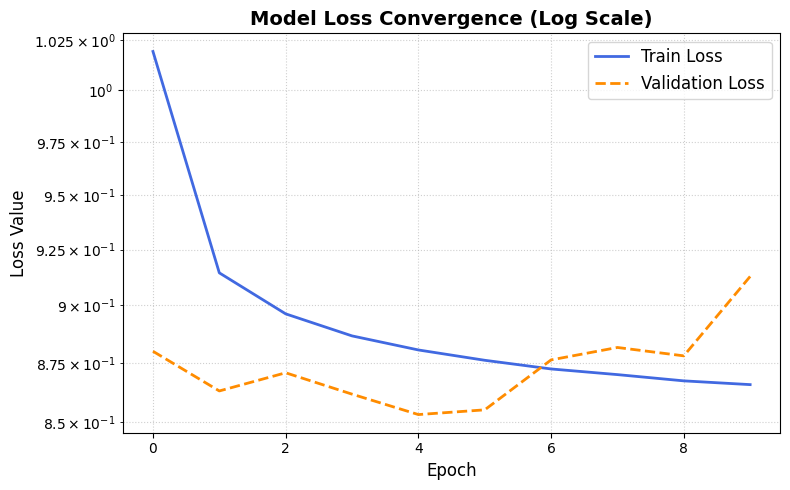

In [43]:
plt.figure(figsize=(8, 5))

plt.semilogy(history.epoch, history.history['loss'], label='Train Loss', color='royalblue', linewidth=2)
plt.semilogy(history.epoch, history.history['val_loss'], label='Validation Loss', color='darkorange', linewidth=2, linestyle='--')

plt.title("Model Loss Convergence (Log Scale)", fontsize=14, fontweight='bold')
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss Value", fontsize=12)
plt.grid(True, which="both", linestyle=':', alpha=0.6) # 'both' grids major/minor log lines
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

In [44]:
#Generating Predictions 

Generating predictions on test data...
485/485 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step
=============== DEBUG CHECKS ===============
Normalized Preds (First 3 entries, Col 0): [ 1.567097    0.46038994 -0.18552987]
Denormalized Pred Mass (First 3 entries):  [809.9144  616.1734  503.09814]
Denormalized Truth Mass (First 3 entries): [664.2622  517.5467  469.72568]


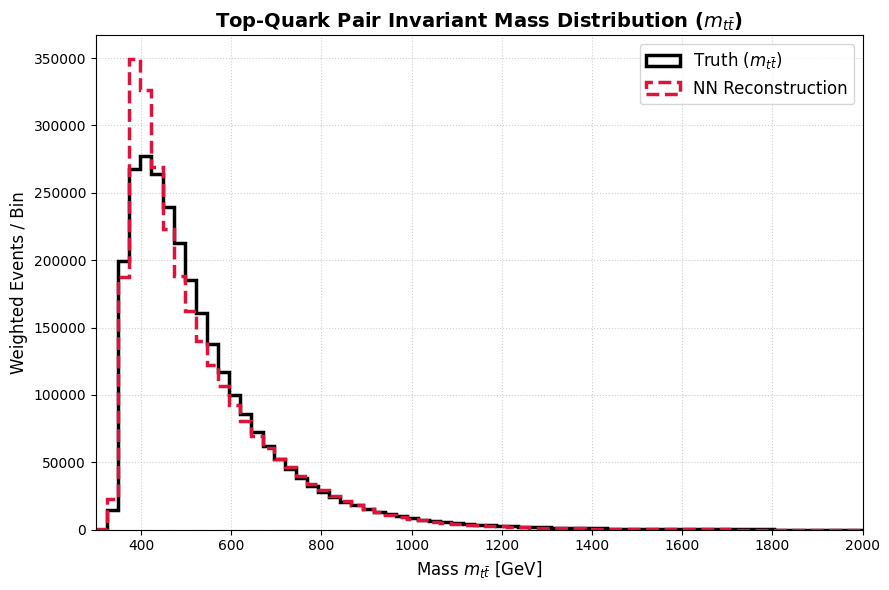

In [45]:
print("Generating predictions on test data...")
predictions_norm = model_improved.predict(X_test, batch_size=8192)

# Checking at the first 3 physical columns
pred_norm_3col = predictions_norm[:, 0:3]

# MANUAL DENORMALIZATION
predictions_physics = target_denorm(pred_norm_3col)
truth_physics = target_denorm(y_test[:, 0:3])

# Extracting the mass (Column 0)
pred_m_ttbar = predictions_physics[:, 0]
truth_m_ttbar = truth_physics[:, 0]

# Extract the event weight (4th column, index 3)
weights = y_test[:, 3]

# Debugging
print("=" * 15 + " DEBUG CHECKS " + "=" * 15)
print(f"Normalized Preds (First 3 entries, Col 0): {predictions_norm[:3, 0]}")
print(f"Denormalized Pred Mass (First 3 entries):  {pred_m_ttbar[:3]}")
print(f"Denormalized Truth Mass (First 3 entries): {truth_m_ttbar[:3]}")
print("=" * 44)

# Plotting Histogram
plt.figure(figsize=(9, 6))

bins = np.linspace(300, 2000, 70) 

# Plotting True Distribution
plt.hist(truth_m_ttbar, bins=bins, weights=weights, histtype='step', 
         linewidth=2.5, color='black', label='Truth ($m_{t\\bar{t}}$)')

# Plotting Model Predictions
plt.hist(pred_m_ttbar, bins=bins, weights=weights, histtype='step', 
         linewidth=2.5, color='crimson', linestyle='--', label='NN Reconstruction')

# Formatting
plt.title("Top-Quark Pair Invariant Mass Distribution ($m_{t\\bar{t}}$)", fontsize=14, fontweight='bold')
plt.xlabel("Mass $m_{t\\bar{t}}$ [GeV]", fontsize=12)
plt.ylabel("Weighted Events / Bin", fontsize=12)
plt.xlim(300, 2000) 
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=12, loc='upper right')

plt.tight_layout()
plt.savefig('ttbar_mass_distribution.png', dpi=300)
plt.show()

In [46]:
#Kinematic Angular Distributions: Delta ttbar and eta_top
#This block evaluates the neural network's performance on the angular and spatial variables. 
#By utilizing variance penalties in our custom loss function, we validate whether the spatial shapes 
#and widths of the distributions match the simulated True values.

485/485 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step


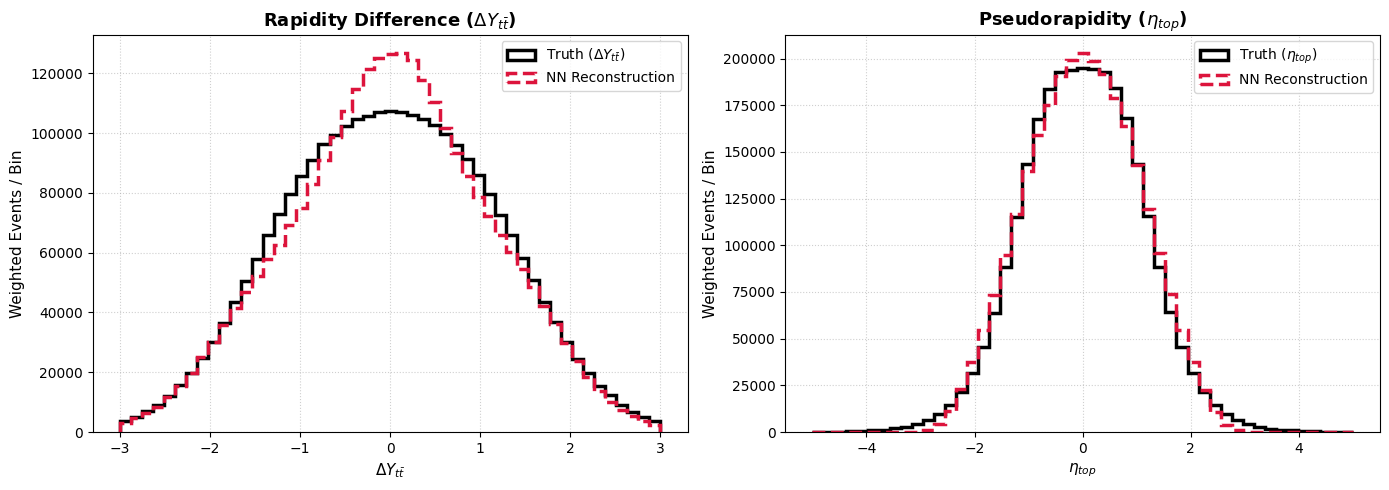

In [47]:
predictions_norm = model_improved.predict(X_test, batch_size=8192)
predictions_physics = target_denorm(predictions_norm[:, 0:3])
truth_physics = target_denorm(y_test[:, 0:3])

# Column 1 = Delta Y, Column 2 = Eta Top
pred_deltaY, true_deltaY = predictions_physics[:, 1], truth_physics[:, 1]
pred_etaTop, true_etaTop = predictions_physics[:, 2], truth_physics[:, 2]
weights = y_test[:, 3]

plt.figure(figsize=(14, 5))

# Plot 1: Rapidity Difference 
plt.subplot(1, 2, 1)
bins_y = np.linspace(-3, 3, 50)
plt.hist(true_deltaY, bins=bins_y, weights=weights, histtype='step', 
         linewidth=2.5, color='black', label=r'Truth ($\Delta Y_{t\bar{t}}$)')
plt.hist(pred_deltaY, bins=bins_y, weights=weights, histtype='step', 
         linewidth=2.5, color='crimson', linestyle='--', label='NN Reconstruction')

plt.title(r"Rapidity Difference ($\Delta Y_{t\bar{t}}$)", fontsize=13, fontweight='bold')
plt.xlabel(r"$\Delta Y_{t\bar{t}}$", fontsize=11)
plt.ylabel("Weighted Events / Bin", fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

#  Plot 2: Pseudorapidity
plt.subplot(1, 2, 2)
bins_eta = np.linspace(-5, 5, 50)

plt.hist(true_etaTop, bins=bins_eta, weights=weights, histtype='step', 
         linewidth=2.5, color='black', label=r'Truth ($\eta_{top}$)')
plt.hist(pred_etaTop, bins=bins_eta, weights=weights, histtype='step', 
         linewidth=2.5, color='crimson', linestyle='--', label='NN Reconstruction')

plt.title(r"Pseudorapidity ($\eta_{top}$)", fontsize=13, fontweight='bold')
plt.xlabel(r"$\eta_{top}$", fontsize=11)
plt.ylabel("Weighted Events / Bin", fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()

plt.savefig('ttbar_angular_distributions.png', dpi=300)
plt.show()

In [48]:
#SHAPLY PlOTS 

Calculating global feature importance across 200 events...


PermutationExplainer explainer: 201it [00:32,  4.88it/s]                        


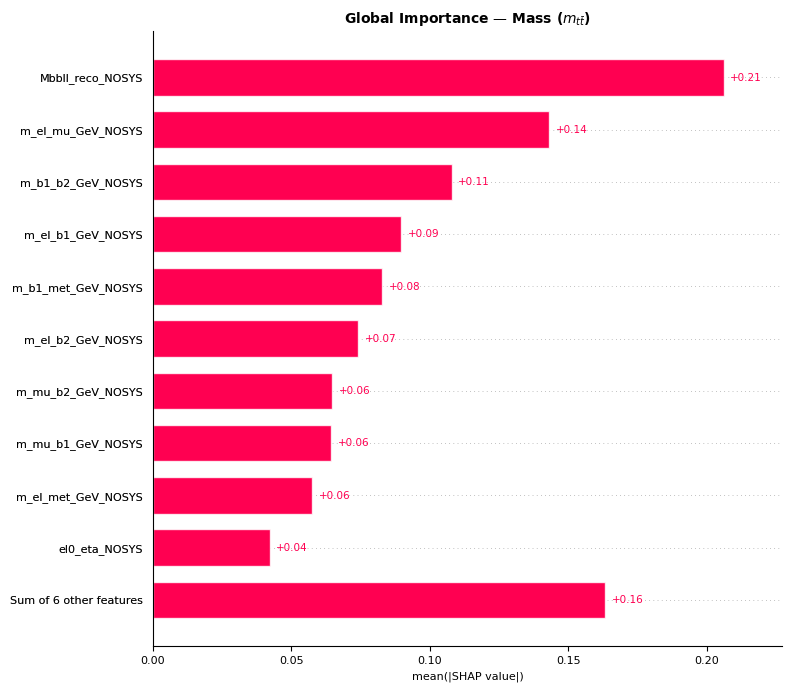

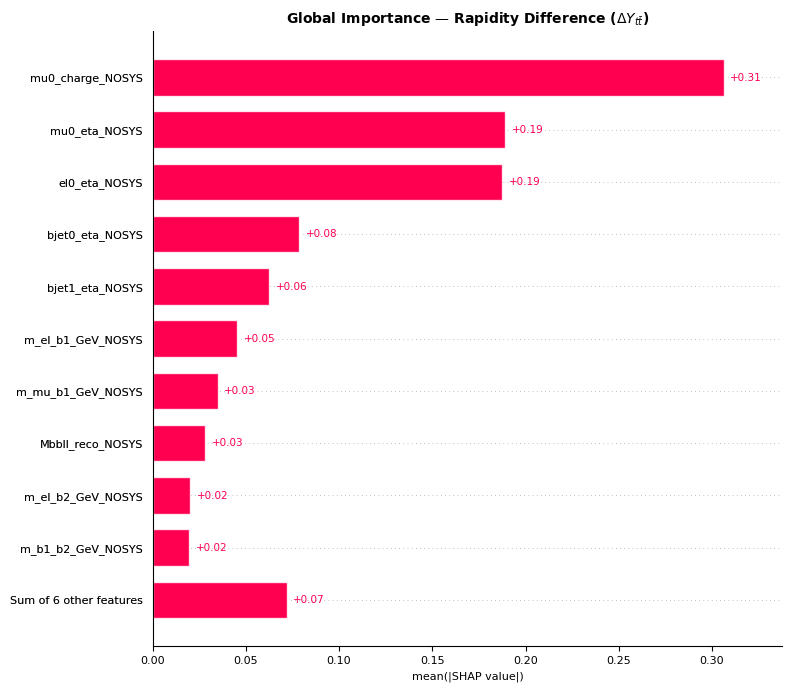

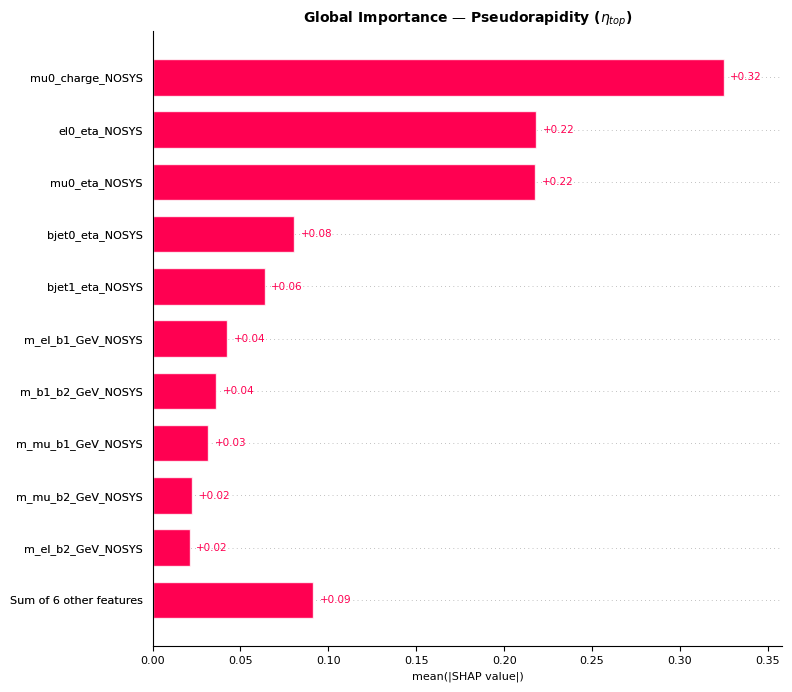

In [49]:
import shap

background = X_test[np.random.choice(X_test.shape[0], 100, replace=False)]

num_samples = 200
test_batch_samples = X_test[np.random.choice(X_test.shape[0], num_samples, replace=False)]

input_features = [
    'Mbbll_reco_NOSYS', 'm_el_mu_GeV_NOSYS', 'm_el_b1_GeV_NOSYS', 'm_el_b2_GeV_NOSYS', 
    'm_mu_b1_GeV_NOSYS', 'm_mu_b2_GeV_NOSYS', 'm_b1_b2_GeV_NOSYS', 'm_b1_met_GeV_NOSYS', 
    'm_b2_met_GeV_NOSYS', 'm_el_met_GeV_NOSYS', 'm_mu_met_GeV_NOSYS', 'el0_eta_NOSYS', 
    'mu0_eta_NOSYS', 'bjet0_eta_NOSYS', 'bjet1_eta_NOSYS', 'mu0_charge_NOSYS'
]

print(f"Calculating global feature importance across {num_samples} events...")
explainer = shap.Explainer(model_improved, background, feature_names=input_features)
shap_values_batch = explainer(test_batch_samples)

target_labels = [r'Mass ($m_{t\bar{t}}$)', r'Rapidity Difference ($\Delta Y_{t\bar{t}}$)', r'Pseudorapidity ($\eta_{top}$)']

for index, target_name in enumerate(target_labels):

    fig = plt.figure(figsize=(5.5, 2.8))
    
    shap_explanation_slice = shap_values_batch[:, :, index]
    
    plt.title(f"Global Importance — {target_name}", 
              fontsize=10, fontweight='bold', pad=6)
    
    shap.plots.bar(shap_explanation_slice, max_display=11, show=False)
    
    plt.tick_params(axis='both', which='major', labelsize=8)
    
    ax = plt.gca()
    ax.xaxis.label.set_size(8) 
    for text in ax.texts:
        text.set_fontsize(7.5)
        
    plt.tight_layout(pad=1.0)
    plt.savefig(f'shap_global_bar_compact_target_{index}.png', dpi=300, bbox_inches='tight')
    plt.show()

In [51]:
#EXPERIMENTAL COMPARISON: REGULAR MSE vs. HYBRID LOSS (BIAS REMOVAL)

In [52]:
def standard_weighted_mse_loss(y_true, y_pred):
    wgt = y_true[:, 3]
    wgtsum = keras.ops.sum(wgt) + 1e-7
    
    sq_err_1 = keras.ops.square(y_true[:, 0] - y_pred[:, 0])
    sq_err_2 = keras.ops.square(y_true[:, 1] - y_pred[:, 1])
    sq_err_3 = keras.ops.square(y_true[:, 2] - y_pred[:, 2])
    
    return keras.ops.sum(wgt * (sq_err_1 + sq_err_2 + sq_err_3)) / wgtsum

In [53]:
model_mse = keras.models.Sequential([
    keras.layers.Input(shape=(16,)),
    keras.layers.BatchNormalization(), 
    
    keras.layers.Dense(256, activation='swish', kernel_initializer='he_normal'),
    keras.layers.Dropout(0.2), 
    
    keras.layers.Dense(128, activation='swish', kernel_initializer='he_normal'),
    keras.layers.Dropout(0.2),
    
    keras.layers.Dense(64, activation='swish', kernel_initializer='he_normal'),
    
    keras.layers.Dense(3, activation='linear')
])

In [54]:
model_mse.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-4),
    loss=standard_weighted_mse_loss
)

In [55]:
print("Training Baseline Model with Regular Weighted MSE Loss...")
history_mse = model_mse.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=40,
    batch_size=2048,
    shuffle=True,
    callbacks=[early_stopping]
)

Training Baseline Model with Regular Weighted MSE Loss...
Epoch 1/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 43s 14ms/step - loss: 0.9466 - val_loss: 0.7324
Epoch 2/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 45s 15ms/step - loss: 0.7501 - val_loss: 0.7018
Epoch 3/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 41s 14ms/step - loss: 0.7174 - val_loss: 0.6872
Epoch 4/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 55s 19ms/step - loss: 0.7015 - val_loss: 0.6851
Epoch 5/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 51s 18ms/step - loss: 0.6916 - val_loss: 0.6855
Epoch 6/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 52s 18ms/step - loss: 0.6851 - val_loss: 0.6748
Epoch 7/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 53s 18ms/step - loss: 0.6806 - val_loss: 0.6728
Epoch 8/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 53s 18ms/step - loss: 0.6768 - val_loss: 0.6755
Epoch 9/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 46s 16ms/step - loss: 0.6737 - val_loss: 0.6639
Epoch 10/40
2909/2909 ━━━━━━━━━━━━━━━━━━━━ 48s 16ms/step - loss: 0.6713 - val_loss: 0.6858
Epoch 11/40
2909/2909 ━━━━━━━━━━━━━━━━━━━

In [56]:
pred_norm_mse = model_mse.predict(X_test, batch_size=8192)
pred_physics_mse = target_denorm(pred_norm_mse[:, 0:3])

pred_m_ttbar_mse = pred_physics_mse[:, 0]
pred_deltaY_mse  = pred_physics_mse[:, 1]
pred_etaTop_mse  = pred_physics_mse[:, 2]

# Extract hybrid predictions (from your existing trained model)
pred_m_ttbar_hybrid = pred_m_ttbar
pred_deltaY_hybrid  = pred_deltaY
pred_etaTop_hybrid  = pred_etaTop

485/485 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step


In [57]:
# VISUALIZATION: TRUTH vs. REGULAR MSE vs. HYBRID LOSS

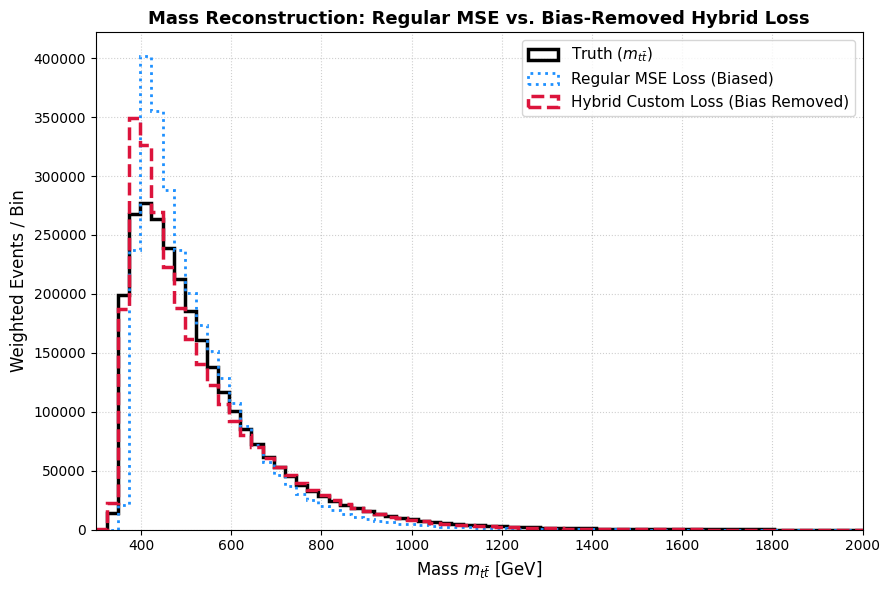

In [58]:
# Plot 1: Mass Distribution Comparison
plt.figure(figsize=(9, 6))
bins_m = np.linspace(300, 2000, 70) 

plt.hist(truth_m_ttbar, bins=bins_m, weights=weights, histtype='step', 
         linewidth=2.5, color='black', label='Truth ($m_{t\\bar{t}}$)')
plt.hist(pred_m_ttbar_mse, bins=bins_m, weights=weights, histtype='step', 
         linewidth=2.0, color='dodgerblue', linestyle=':', label='Regular MSE Loss (Biased)')
plt.hist(pred_m_ttbar_hybrid, bins=bins_m, weights=weights, histtype='step', 
         linewidth=2.5, color='crimson', linestyle='--', label='Hybrid Custom Loss (Bias Removed)')

plt.title("Mass Reconstruction: Regular MSE vs. Bias-Removed Hybrid Loss", fontsize=13, fontweight='bold')
plt.xlabel("Mass $m_{t\\bar{t}}$ [GeV]", fontsize=12)
plt.ylabel("Weighted Events / Bin", fontsize=12)
plt.xlim(300, 2000) 
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.savefig('ttbar_mass_mse_vs_hybrid.png', dpi=300)
plt.show()

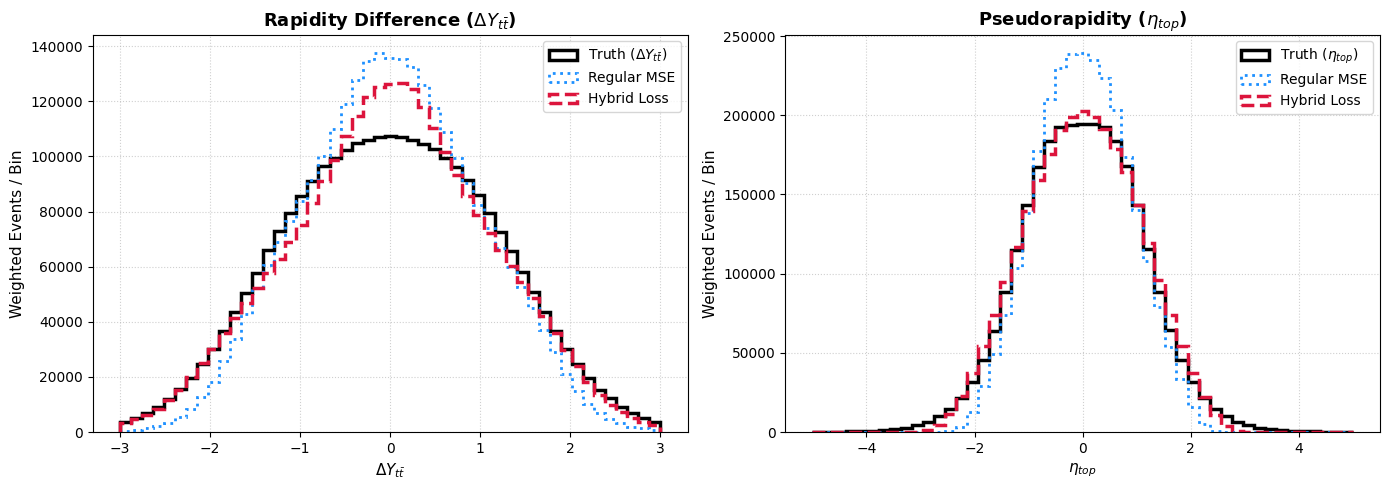

In [59]:
plt.figure(figsize=(14, 5))

# Rapidity Difference
plt.subplot(1, 2, 1)
bins_y = np.linspace(-3, 3, 50)
plt.hist(true_deltaY, bins=bins_y, weights=weights, histtype='step', 
         linewidth=2.5, color='black', label=r'Truth ($\Delta Y_{t\bar{t}}$)')
plt.hist(pred_deltaY_mse, bins=bins_y, weights=weights, histtype='step', 
         linewidth=2.0, color='dodgerblue', linestyle=':', label='Regular MSE')
plt.hist(pred_deltaY_hybrid, bins=bins_y, weights=weights, histtype='step', 
         linewidth=2.5, color='crimson', linestyle='--', label='Hybrid Loss')

plt.title(r"Rapidity Difference ($\Delta Y_{t\bar{t}}$)", fontsize=13, fontweight='bold')
plt.xlabel(r"$\Delta Y_{t\bar{t}}$", fontsize=11)
plt.ylabel("Weighted Events / Bin", fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

# Pseudorapidity
plt.subplot(1, 2, 2)
bins_eta = np.linspace(-5, 5, 50)
plt.hist(true_etaTop, bins=bins_eta, weights=weights, histtype='step', 
         linewidth=2.5, color='black', label=r'Truth ($\eta_{top}$)')
plt.hist(pred_etaTop_mse, bins=bins_eta, weights=weights, histtype='step', 
         linewidth=2.0, color='dodgerblue', linestyle=':', label='Regular MSE')
plt.hist(pred_etaTop_hybrid, bins=bins_eta, weights=weights, histtype='step', 
         linewidth=2.5, color='crimson', linestyle='--', label='Hybrid Loss')

plt.title(r"Pseudorapidity ($\eta_{top}$)", fontsize=13, fontweight='bold')
plt.xlabel(r"$\eta_{top}$", fontsize=11)
plt.ylabel("Weighted Events / Bin", fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('ttbar_angular_mse_vs_hybrid.png', dpi=300)
plt.show()